<a href="https://colab.research.google.com/github/PatzerATX/image-classification-evolution/blob/main/Evolution_of_Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#CS 4337: The Evolution of Image Classification

How do image representation and model architecture affect classification performance as visual complexity increases?

##0. Setup

This section imports the necessary libraries, sets the random seeds for the program, and defines path directories.

In [ ]:
import random

import numpy as np
import torch
import pandas as pd

from pathlib import Path
from google.colab import drive
from torchvision.datasets import MNIST, CIFAR10
from torchvision import transforms
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split

SEED = 1234 #Random seed to maintain reproducibility
MAX_ITER = 1000 # Maximum number of iterations allowed during training
TOL = 1e-3 # Tolerance threshold for convergence

drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/CS4337_Project1/data")
OUTPUT_DIR = Path("/content/drive/MyDrive/CS4337_Project1/output")

# Set random seeds to make random operations reproducible
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Create the directories if they don't already exist
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Random seed: {SEED}")
print(f"Data directory: {DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Random seed: 1234
Data directory: /content/drive/MyDrive/CS4337_Project1/data
Output directory: /content/drive/MyDrive/CS4337_Project1/output


##1. Data Loading and Preparation

This section loads the MNIST and CIFAR-10 datasets, then divides each training set into training (80%) and validation (20%) subsets.

###1.1 Load the Datasets

The MNIST and CIFAR-10 training and testing datasets are downloaded. A 'ToTensor()' transformation is assigned to each dataset. This transformation is applied when an individual image is accessed through 'dataset[index]'. It converts pixel values from 0-255 to 0.0-1.0 and arranges the image in channel-first order. The original images stored in '.data' remain unchanged.

In [ ]:
# ToTensor() converts image values (0-255) into normalized values (0.0-1.0)
# and arranges them into a PyTorch tensor for later use

mnist_original = MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transforms.ToTensor() # Normalizes and arranges as 1 x 28 x 28
)

mnist_test = MNIST(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transforms.ToTensor() # Normalizes and arranges as 1 x 28 x 28
)

cifar10_original = CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transforms.ToTensor() # Normalizes and arranges as 3 x 32 x 32
)

cifar10_test = CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transforms.ToTensor() # Normalizes and arranges as 3 x 32 x 32
)

print(f"mnist_original length: {len(mnist_original)}")
print(f"mnist_test length: {len(mnist_test)}")
print(f"cifar10_original length: {len(cifar10_original)}")
print(f"cifar10_test length: {len(cifar10_test)}")


mnist_original length: 60000
mnist_test length: 10000
cifar10_original length: 50000
cifar10_test length: 10000


###1.2 Divide Datasets

The original training sets are divided into training (80%) and validation (20%) subsets. A fixed random seed makes the split reproducible, while stratification maintains approximately the same class distribution in both subsets. The official test sets remain separate and are not involved in the split.

In [ ]:
def split_data(dataset):
  """Split the dataset into stratified training and validation subsets."""

  indices = np.arange(len(dataset)) # Creates an array of incremental indices
  labels = np.asarray(dataset.targets) # Creates an array of the dataset labels

  # train_test_split uses SEED to split data randomly, with 20% going to
  # val_indices. It also uses labels to stratify those results so each subset
  # maintains the same label ratio as the original dataset.
  train_indices, val_indices = train_test_split(
      indices, # Indices being divided
      test_size=0.2, # 20% of division goes into val_indices
      random_state=SEED, # use random seed constant
      stratify=labels # maintain label distribution within full dataset in each subset
  )

  # Subsets of the original dataset are created. The Subset method maintains a
  # reference to the original dataset, without copying it, that the indices
  # can access.
  train_data = Subset(dataset, train_indices)
  val_data = Subset(dataset, val_indices)

  return train_data, val_data

mnist_train, mnist_val = split_data(mnist_original)
cifar10_train, cifar10_val = split_data(cifar10_original)

print(f"mnist_train length: {len(mnist_train)}")
print(f"mnist_val length: {len(mnist_val)}")
print(f"cifar10_train length: {len(cifar10_train)}")
print(f"cifar10_val length: {len(cifar10_val)}")

mnist_train length: 48000
mnist_val length: 12000
cifar10_train length: 40000
cifar10_val length: 10000


##2. Work Package 1: Raw-Pixel Linear Baselines

Each image is flattened into a single feature vector containing its raw pixel values. The features are standardized with 'StandardScaler()', and multiclass logistic regression is used to create a baseline or comparison with later models.

###2.0.1 Convert Image to Flattened Array for Logistic Regression

For each dataset, the original images stored in '.data' are used for efficiency instead of the 'ToTensor()' transformations. The result of 'ToTensor()' is not permanently saved. The transformation is performed each time an image is accessed through 'dataset[index]', producing a new tensor. If we used those transformed images for logistic regression, every image would first need to pass through 'ToTensor()'. We would then combine the tensors, convert them into a NumPy array, and flatten each image for scikit-learn. Accessing .data allows NumPy to prepare all the images more efficiently as one large array. 'ToTensor()' will be useful later when training the neural networks and CNNs with PyTorch.

The pixel values are not divided by 255 in this section because 'StandardScaler()' will standardize every pixel feature. Each image is flattened into 784 features for MNIST or 3,072 features for CIFAR-10. The resulting values are converted to 'float32' to reduce memory usage.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from time import perf_counter


def prepare_raw_pixel_data(data_source):
  """Return flattened raw-pixel features and their labels."""

  if isinstance(data_source, Subset): # If data_source is train or val subset
    original_dataset = data_source.dataset # Points to original full dataset
    selected_indices = data_source.indices # Indices assigned to this data_source
  else:
    original_dataset = data_source # If data_source is test
    selected_indices = np.arange(len(data_source)) # Use all values in test

  images = np.asarray(original_dataset.data)[selected_indices] # Creates NumPy array of images
  labels = np.asarray(original_dataset.targets)[selected_indices] # Creates matching NumPy array of label values

  # Now we want to flatten the pixel values for each image to be a continuous array of pixel values instead of matrix
  # They're then converted to float32 type
  features = images.reshape(len(images), -1).astype(np.float32) # float32 used to conserve memory

  return features, labels # feature vectors and corresponding labels are returned


###2.0.2 Perform Multiclass Logistic Regression Training and Validation

A pipeline connects 'StandardScaler()' and logistic regression. During training, the scaler calculates the mean and standard deviation of each pixel feature using only the training data. Logistic regression is then trained using those standardized features. When validation data is supplied, the pipeline applies the same training-set means and standard deviations before making predictions.

Validation accuracy measures how well the model performs on images that were not used to fit the model.

The recorded training time includes both fitting the scaler and training logistic regression.

In [ ]:

def train_raw_pixel_logistic_regression(dataset_name, train_data, val_data):
  """Train and validate a raw-pixel logistic regression model."""

  train_features, train_labels = prepare_raw_pixel_data(train_data)
  val_features, val_labels = prepare_raw_pixel_data(val_data)

  model = make_pipeline(
      StandardScaler(),
      # Values will be adjusted to near a mean of 0 with SD of 1.
      # This puts each feature on a comparable scale and helps model optimization.
      LogisticRegression(max_iter=MAX_ITER, tol=TOL)
      )

  training_start = perf_counter()
  model.fit(train_features, train_labels)
  training_end = perf_counter()

  training_time = training_end - training_start

  val_predictions = model.predict(val_features)
  val_accuracy = accuracy_score(val_labels, val_predictions)

  print(f"Dataset: {dataset_name}")
  print(f"Validation accuracy: {val_accuracy:.4f}")
  print(f"Training time: {training_time:.2f} seconds")

  return model, val_accuracy, training_time



###2.0.3 Perform Multiclass Logistic Regression Testing

The trained pipeline is applied to the official test set. The pipeline standardizes the test features using the values learned from the training set, predicts the image class, and calculates test accuracy. The test set is not used to train the model.

In [ ]:
def test_raw_pixel_logistic_regression(model, test_data):
  """Evaluate a raw-pixel model on the test set."""

  test_features, test_labels = prepare_raw_pixel_data(test_data)

  test_predictions = model.predict(test_features)
  test_accuracy = accuracy_score(test_labels, test_predictions)

  print(f"Test accuracy: {test_accuracy:.4f}")

  return test_accuracy

###2.1 MNIST

In [ ]:
mnist_model, mnist_val_accuracy, mnist_training_time = train_raw_pixel_logistic_regression("MNIST", mnist_train, mnist_val)

mnist_test_accuracy = test_raw_pixel_logistic_regression(mnist_model, mnist_test)


Dataset: MNIST
Validation accuracy: 0.9136
Training time: 11.86 seconds
Test accuracy: 0.9230


###2.2 CIFAR-10

In [ ]:
# Maximum iteration values of 500 and 1000 did not converge for CIFAR-10.
# Tolerance threshold raised from default 1e-4 to 1e-3 across models.
cifar10_model, cifar10_val_accuracy, cifar10_training_time = train_raw_pixel_logistic_regression("CIFAR-10", cifar10_train, cifar10_val)

cifar10_test_accuracy = test_raw_pixel_logistic_regression(cifar10_model, cifar10_test)

Dataset: CIFAR-10
Validation accuracy: 0.3624
Training time: 283.31 seconds
Test accuracy: 0.3655


###2.3 Work Package 1 Results

In [ ]:
wp1_results_table = pd.DataFrame([
    {
        "Dataset": "MNIST",
        "Representation": "Raw pixels",
        "Classifier": "Logistic regression",
        "Feature length": 784, # (1 x 28 x 28)
        "Validation accuracy": mnist_val_accuracy,
        "Test accuracy": mnist_test_accuracy,
        "Training time (s)": mnist_training_time,
    },
    {
        "Dataset": "CIFAR-10",
        "Representation": "Raw pixels",
        "Classifier": "Logistic regression",
        "Feature length": 3072, # (3 x 32 x 32)
        "Validation accuracy": cifar10_val_accuracy,
        "Test accuracy": cifar10_test_accuracy,
        "Training time (s)": cifar10_training_time,
    },
])

wp1_results_table["Settings"] = (
    f"C=1.0, max_iter={MAX_ITER}, tol={TOL}"
)

wp1_results_table.to_csv(
    OUTPUT_DIR / "work_package_1_results.csv",
    index=False
)

display(
    wp1_results_table.style.format({
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

,Dataset,Representation,Classifier,Feature length,Validation accuracy,Test accuracy,Training time (s),Settings
0,MNIST,Raw pixels,Logistic regression,784,0.9136,0.9230,11.86,"C=1.0, max_iter=1000, tol=0.001"
1,CIFAR-10,Raw pixels,Logistic regression,3072,0.3624,0.3655,283.31,"C=1.0, max_iter=1000, tol=0.001"


##3. Work Package 2: HOG Representations

Work Package 2 replaces raw pixels with Histogram of Oriented Gradients (HOG), while keeping logistic regression and the fixed data splits unchanged. For each dataset, orientation bin counts of 6, 9, and 12 are compared using the validation set accuracy. The selected setting is then evaluated using the official test set.

###3.0.1 Prepare Grayscale Images

The selected images and labels are retrieved from the original dataset. CIFAR-10 images are converted from RGB to grayscale, and MNIST images are scaled to values between 0 and 1.

In [ ]:
from skimage.color import rgb2gray
from skimage.feature import hog

HOG_ORIENTATIONS = (6, 9, 12) # Number of gradient orientation bins to try

def prepare_hog_images(data_source):
  """Return grayscale images and their labels for HOG extraction."""

  if isinstance(data_source, Subset): # If source is train or val subsets
    original_dataset = data_source.dataset
    selected_indices = data_source.indices
  else:
    original_dataset = data_source # If source is test set
    selected_indices = np.arange(len(data_source))

  images = np.asarray(original_dataset.data)[selected_indices]
  labels = np.asarray(original_dataset.targets)[selected_indices]

  if images.ndim == 4: # CIFAR-10 (# images x 32 x 32 x 3) converted to grayscale 0-1
    images = rgb2gray(images).astype(np.float32)
  else: # MNIST (# images x 28 x 28) converted to 0-1
    images = images.astype(np.float32) / 255.0

  return images, labels

###3.0.2 Extract HOG features

Each grayscale image is divided into fixed cells and overlapping blocks. HOG creates a normalized feature vector from the gradient-orientation histograms. This function repeats that process for every image and returns the resulting HOG feature vectors as a NumPy array.

In [ ]:
def extract_hog_features(images, orientations):
  """Create a HOG feature vector for each image."""

  features = [] # List of all image feature vectors

  for image in images:
    image_features = hog(
        image, # Grayscale image
        orientations=orientations, # Number of direction bins in histogram
        pixels_per_cell=(4, 4), # Pixels per cell
        cells_per_block=(2, 2), # Cells per normalization block
        block_norm="L2-Hys", # Block normalization method
        feature_vector=True, # Returns one-dimensional feature vector
    )

    features.append(image_features) # Each image feature vector is added to features list

  features = np.asarray(features, dtype=np.float32) # Features list is converted to NumPy 2d array
  return features

###3.0.3 Train and Validate HOG + Logistic Regression

For each orientation-bin setting, HOG features are extracted from the fixed training and validation subsets. The features are standardized, and logistic regression is trained for each setting. Validation accuracy determines which orientation count is selected.

In [ ]:
def train_and_select_hog_model(dataset_name, train_data, val_data):
  """Train one HOG model per orientation count and keep the best one."""
  train_images, train_labels = prepare_hog_images(train_data)
  val_images, val_labels = prepare_hog_images(val_data)

  candidate_results = [] # Holds results for each orientation setting
  best_result = None # Stores the best result and its trained model
  best_hog_data = None # Stores selected hog dataset

  for orientation in HOG_ORIENTATIONS: # Each bin quantity is attempted
    print(f"{dataset_name}: extracting HOG features with {orientation} orientation bins...")

    train_features = extract_hog_features(train_images, orientation) # HOG extracted from training set
    val_features = extract_hog_features(val_images, orientation) # HOG extracted from val set

    model = make_pipeline( # LogisticRegression training pipeline initialized with same MAX and TOL as raw_pixel
        StandardScaler(),
        LogisticRegression(
            max_iter=MAX_ITER, # Max iterations
            C=1.0, # Regularization parameter
            tol=TOL, # Tolerance allowed
        ),
    )

    training_start = perf_counter()
    model.fit(train_features, train_labels) # Training performed
    training_end = perf_counter()

    training_time = training_end - training_start

    train_predictions = model.predict(train_features)
    train_accuracy = accuracy_score(train_labels, train_predictions)

    val_predictions = model.predict(val_features)
    val_accuracy = accuracy_score(val_labels, val_predictions)

    result = {
        "Dataset": dataset_name,
        "Orientations": orientation,
        "Feature Length": train_features.shape[1],
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Training Time (s)": training_time
    }

    candidate_results.append(result) # Results for this orientation are appended

    if (
        best_result is None
        or val_accuracy > best_result["Validation Accuracy"]
    ):
        best_result = result.copy() # Copy the best performer's recorded results
        best_result["model"] = model # Add selected model pipeline to dictionary

        best_hog_data = { # HOG feature data for chosen model
            "train_features": train_features,
            "train_labels": train_labels,
            "val_features": val_features,
            "val_labels": val_labels,
        }

  # Return results table, best model, and associated HOG features
  return pd.DataFrame(candidate_results), best_result, best_hog_data


###3.0.4 Test the selected model

After validation selects the best orientation count, HOG features are extracted from the test set. The pipeline then predicts the test labels and calculates the final accuracy.

In [ ]:
def test_selected_hog_model(best_result, test_data):
  """Evaluate the selected HOG model on the test set."""
  test_images, test_labels = prepare_hog_images(test_data)
  test_features = extract_hog_features(
      test_images,
      best_result["Orientations"], # Bin number from best_result used on test_data
  )

  test_predictions = best_result["model"].predict(test_features) # best_result model used
  test_accuracy = accuracy_score(test_labels, test_predictions)

  print(f"Test accuracy: {test_accuracy:.4f}")

  return test_accuracy, test_features, test_labels

###3.1 HOG + Logistic Regression - MNIST

HOG features are extracted from the fixed MNIST training and validation subsets for 6, 9, and 12 orientation bins. Validation accuracy selects the final orientation count before the official test set is processed.

In [ ]:
# Train and validate the three MNIST HOG configurations
mnist_hog_candidates, mnist_hog_best, mnist_hog_data = train_and_select_hog_model(
    "MNIST",
    mnist_train,
    mnist_val
)

# Test the configuration selected using validation accuracy
mnist_hog_test_accuracy, mnist_hog_test_features, mnist_hog_test_labels = test_selected_hog_model(
    mnist_hog_best,
    mnist_test
)

display(mnist_hog_candidates)

print(f"Selected orientations: {mnist_hog_best['Orientations']}")
print(f"Validation accuracy: {mnist_hog_best['Validation Accuracy']:.4f}")
print(f"Test accuracy: {mnist_hog_test_accuracy:.4f}")

MNIST: extracting HOG features with 6 orientation bins...
MNIST: extracting HOG features with 9 orientation bins...
MNIST: extracting HOG features with 12 orientation bins...
Test accuracy: 0.9786


,Dataset,Orientations,Feature Length,Training Accuracy,Validation Accuracy,Training Time (s)
0,MNIST,6,864,0.985333,0.974083,3.730873
1,MNIST,9,1296,0.988021,0.976583,5.035187
2,MNIST,12,1728,0.990958,0.977083,6.490457


Selected orientations: 12
Validation accuracy: 0.9771
Test accuracy: 0.9786


###3.2 HOG + Logistic Regression - CIFAR-10

Each CIFAR-10 image is converted from RGB to grayscale before HOG extraction. The same HOG settings, orientation candidates, logistic regression settings, and fixed split are used so that orientation bins are the only changing variable.

In [ ]:
# Train and validate the three CIFAR-10 HOG configurations
cifar_hog_candidates, cifar_hog_best, cifar_hog_data = train_and_select_hog_model(
    "CIFAR-10",
    cifar10_train,
    cifar10_val
)

# Test the configuration selected using validation accuracy
cifar_hog_test_accuracy, cifar_hog_test_features, cifar_hog_test_labels = test_selected_hog_model(
    cifar_hog_best,
    cifar10_test
)

display(cifar_hog_candidates)

print(f"Selected orientations: {cifar_hog_best['Orientations']}")
print(f"Validation accuracy: {cifar_hog_best['Validation Accuracy']:.4f}")
print(f"Test accuracy: {cifar_hog_test_accuracy:.4f}")


CIFAR-10: extracting HOG features with 6 orientation bins...
CIFAR-10: extracting HOG features with 9 orientation bins...
CIFAR-10: extracting HOG features with 12 orientation bins...
Test accuracy: 0.5084


,Dataset,Orientations,Feature Length,Training Accuracy,Validation Accuracy,Training Time (s)
0,CIFAR-10,6,1176,0.597925,0.5157,27.091477
1,CIFAR-10,9,1764,0.644000,0.5140,48.601673
2,CIFAR-10,12,2352,0.676825,0.5066,58.446393


Selected orientations: 6
Validation accuracy: 0.5157
Test accuracy: 0.5084


###3.3 Work Package 2 Results

The final table records the selected orientation count, feature length, validation accuracy, test accuracy, and HOG training time for both datasets.

In [ ]:
wp2_results_table = pd.DataFrame([
    {
        "Dataset": "MNIST",
        "Selected orientations": mnist_hog_best["Orientations"],
        "Feature length": mnist_hog_best["Feature Length"],
        "Validation accuracy": mnist_hog_best["Validation Accuracy"],
        "Test accuracy": mnist_hog_test_accuracy,
        "HOG training time (s)": mnist_hog_best["Training Time (s)"],
    },

    {
        "Dataset": "CIFAR-10",
        "Selected orientations": cifar_hog_best["Orientations"],
        "Feature length": cifar_hog_best["Feature Length"],
        "Validation accuracy": cifar_hog_best["Validation Accuracy"],
        "Test accuracy": cifar_hog_test_accuracy,
        "HOG training time (s)": cifar_hog_best["Training Time (s)"],
    },
])

wp2_results_table.to_csv(
    OUTPUT_DIR / "work_package_2_results.csv",
    index=False,
)

display(
    wp2_results_table.style.format({
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "HOG training time (s)": "{:.2f}",
    })
)

mnist_comparison_table = pd.DataFrame([
    {
        "Representation": "Raw pixels",
        "Selected setting": "C=1.0",
        "Feature length": 784,
        "Validation accuracy": mnist_val_accuracy,
        "Test accuracy": mnist_test_accuracy,
        "Training time (s)": mnist_training_time,
    },
    {
        "Representation": "HOG",
        "Selected setting": (
            f"{mnist_hog_best['Orientations']} orientation bins"
        ),
        "Feature length": mnist_hog_best["Feature Length"],
        "Validation accuracy": mnist_hog_best["Validation Accuracy"],
        "Test accuracy": mnist_hog_test_accuracy,
        "Training time (s)": mnist_hog_best["Training Time (s)"],
    },
])

print("MNIST: Raw Pixels vs. Selected HOG")

display(
    mnist_comparison_table.style.format({
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

cifar10_comparison_table = pd.DataFrame([
    {
        "Representation": "Raw pixels",
        "Selected setting": "C=1.0",
        "Feature length": 3072,
        "Validation accuracy": cifar10_val_accuracy,
        "Test accuracy": cifar10_test_accuracy,
        "Training time (s)": cifar10_training_time,
    },
    {
        "Representation": "HOG",
        "Selected setting": (
            f"{cifar_hog_best['Orientations']} orientation bins"
        ),
        "Feature length": cifar_hog_best["Feature Length"],
        "Validation accuracy": cifar_hog_best["Validation Accuracy"],
        "Test accuracy": cifar_hog_test_accuracy,
        "Training time (s)": cifar_hog_best["Training Time (s)"],
    },
])

print("CIFAR-10: Raw Pixels vs. Selected HOG")

display(
    cifar10_comparison_table.style.format({
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

,Dataset,Selected orientations,Feature length,Validation accuracy,Test accuracy,HOG training time (s)
0,MNIST,12,1728,0.9771,0.9786,6.49
1,CIFAR-10,6,1176,0.5157,0.5084,27.09


MNIST: Raw Pixels vs. Selected HOG


,Representation,Selected setting,Feature length,Validation accuracy,Test accuracy,Training time (s)
0,Raw pixels,C=1.0,784,0.9136,0.9230,11.86
1,HOG,12 orientation bins,1728,0.9771,0.9786,6.49


CIFAR-10: Raw Pixels vs. Selected HOG


,Representation,Selected setting,Feature length,Validation accuracy,Test accuracy,Training time (s)
0,Raw pixels,C=1.0,3072,0.3624,0.3655,283.31
1,HOG,6 orientation bins,1176,0.5157,0.5084,27.09


##4. Work Package 3: Selected HOG + Linear SVM

Work Package 3 keeps the selected HOG representation from Work Package 2 fixed and replaces logistic regression with a linear Support Vector Machine. For each dataset, C values of 0.1, 1, and 10 are compared using validation accuracy. The selected model is then evaluated on the test set.

###4.01 Train and Select SVM Model

In [ ]:
from sklearn.svm import LinearSVC

SVM_C_VALUES = (0.1, 1, 10)
# C constant controls how strongly SVM penalizes misclassified examples
# and examples inside the margin.
# Large C = narrower margin, difficult examples have more influence, overfitting risk
# Small C = wider margin with smaller weights, accepts some violations, underfitting risk

def train_and_select_svm(dataset_name, hog_data):
    """Train one linear SVM per C value and keep the best model."""
    candidate_results = []
    best_result = None

    for c_value in SVM_C_VALUES:
        print(f"{dataset_name}: training SVM with C={c_value}...")
        model = make_pipeline(
            StandardScaler(),
            # Standardizes each feature column across all training images.
            # Puts all feature columns on comparable numeric scales so one
            # feature doesn't dominate decisions
            LinearSVC(
                C=c_value, # C constant
                max_iter=10000, # Maximum number of allowed iterations
                tol=TOL, # Tolerance constant
                dual=False,
            ),
        )

        training_start = perf_counter()

        # Training performed
        model.fit(
            hog_data["train_features"],
            hog_data["train_labels"],
        )

        training_end = perf_counter()
        training_time = training_end - training_start

        # Predict training images
        train_predictions = model.predict(
            hog_data["train_features"]
        )

        # Training images prediction accuracy
        train_accuracy = accuracy_score(
            hog_data["train_labels"],
            train_predictions,
        )

        # Predict validation images
        val_predictions = model.predict(
            hog_data["val_features"]
        )

        # Validation images prediction accuracy
        val_accuracy = accuracy_score(
            hog_data["val_labels"],
            val_predictions,
        )

        result = {
            "Dataset": dataset_name,
            "C": c_value,
            "Training Accuracy": train_accuracy,
            "Validation Accuracy": val_accuracy,
            "Training Time (s)": training_time,
        }

        candidate_results.append(result)

        # Best validation accuracy model is kept
        if (
            best_result is None
            or val_accuracy > best_result["Validation Accuracy"]
        ):
            best_result = result.copy()
            best_result["model"] = model

    return pd.DataFrame(candidate_results), best_result

###4.0.2 Test the Selected SVM Model


In [ ]:
def test_selected_svm(best_result, test_features, test_labels):
    """Evaluate the selected linear SVM on the test set."""
    test_predictions = best_result["model"].predict(
        test_features
    )

    test_accuracy = accuracy_score(
        test_labels,
        test_predictions,
    )

    print(f"Test accuracy: {test_accuracy:.4f}")

    return test_accuracy

###4.1 Selected HOG + Linear SVM - MNIST

The 12-orientation HOG representation selected in Work Package 2 is kept
fixed. Linear SVM models with C values of 0.1, 1, and 10 are compared using
MNIST validation accuracy.

In [ ]:
mnist_svm_candidates, mnist_svm_best = train_and_select_svm(
    "MNIST",
    mnist_hog_data,
)

mnist_svm_test_accuracy = test_selected_svm(
    mnist_svm_best,
    mnist_hog_test_features,
    mnist_hog_test_labels,
)

display(mnist_svm_candidates)

print(f"Selected C: {mnist_svm_best['C']}")
print(
    f"Validation accuracy: "
    f"{mnist_svm_best['Validation Accuracy']:.4f}"
)
print(f"Test accuracy: {mnist_svm_test_accuracy:.4f}")

MNIST: training SVM with C=0.1...
MNIST: training SVM with C=1...
MNIST: training SVM with C=10...
Test accuracy: 0.9774


,Dataset,C,Training Accuracy,Validation Accuracy,Training Time (s)
0,MNIST,0.1,0.999542,0.976417,334.552192
1,MNIST,1.0,1.000000,0.972917,765.291173
2,MNIST,10.0,1.000000,0.971083,887.402409


Selected C: 0.1
Validation accuracy: 0.9764
Test accuracy: 0.9774


### 4.2 Selected HOG + Linear SVM - CIFAR-10

The 6-orientation HOG representation selected in Work Package 2 is kept
fixed. Linear SVM models with C values of 0.1, 1, and 10 are compared using
CIFAR-10 validation accuracy.

In [ ]:
cifar_svm_candidates, cifar_svm_best = train_and_select_svm(
    "CIFAR-10",
    cifar_hog_data,
)

cifar_svm_test_accuracy = test_selected_svm(
    cifar_svm_best,
    cifar_hog_test_features,
    cifar_hog_test_labels,
)

display(cifar_svm_candidates)

print(f"Selected C: {cifar_svm_best['C']}")
print(
    f"Validation accuracy: "
    f"{cifar_svm_best['Validation Accuracy']:.4f}"
)
print(f"Test accuracy: {cifar_svm_test_accuracy:.4f}")

CIFAR-10: training SVM with C=0.1...
CIFAR-10: training SVM with C=1...
CIFAR-10: training SVM with C=10...
Test accuracy: 0.5086


,Dataset,C,Training Accuracy,Validation Accuracy,Training Time (s)
0,CIFAR-10,0.1,0.587725,0.5175,234.682477
1,CIFAR-10,1.0,0.587775,0.5167,235.535951
2,CIFAR-10,10.0,0.587700,0.5166,240.285522


Selected C: 0.1
Validation accuracy: 0.5175
Test accuracy: 0.5086


### 4.3 Work Package 3 Results

The final table records the HOG configuration inherited from Work Package 2,
the selected C value, training accuracy, validation accuracy, test accuracy,
and SVM training time. Separate comparison tables show the effect of changing
the classifier while keeping the HOG representation fixed.

In [ ]:
wp3_results_table = pd.DataFrame([
    {
        "Dataset": "MNIST",
        "HOG orientations": mnist_hog_best["Orientations"],
        "Feature length": mnist_hog_best["Feature Length"],
        "Selected C": mnist_svm_best["C"],
        "Training accuracy": mnist_svm_best["Training Accuracy"],
        "Validation accuracy": mnist_svm_best["Validation Accuracy"],
        "Test accuracy": mnist_svm_test_accuracy,
        "SVM training time (s)": mnist_svm_best["Training Time (s)"],
    },
    {
        "Dataset": "CIFAR-10",
        "HOG orientations": cifar_hog_best["Orientations"],
        "Feature length": cifar_hog_best["Feature Length"],
        "Selected C": cifar_svm_best["C"],
        "Training accuracy": cifar_svm_best["Training Accuracy"],
        "Validation accuracy": cifar_svm_best["Validation Accuracy"],
        "Test accuracy": cifar_svm_test_accuracy,
        "SVM training time (s)": cifar_svm_best["Training Time (s)"],
    },
])

wp3_results_table.to_csv(
    OUTPUT_DIR / "work_package_3_results.csv",
    index=False,
)

print("Inherited HOG configurations\n")

display(
    wp3_results_table.style.format({
        "Training accuracy": "{:.4f}",
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "SVM training time (s)": "{:.2f}",
    })
)

mnist_svm_comparison = pd.DataFrame([
    {
        "Classifier": "Logistic regression",
        "Selected setting": "C=1.0",
        "Training accuracy": mnist_hog_best["Training Accuracy"],
        "Validation accuracy": mnist_hog_best["Validation Accuracy"],
        "Test accuracy": mnist_hog_test_accuracy,
        "Training time (s)": mnist_hog_best["Training Time (s)"],
    },
    {
        "Classifier": "Linear SVM",
        "Selected setting": f"C={mnist_svm_best['C']}",
        "Training accuracy": mnist_svm_best["Training Accuracy"],
        "Validation accuracy": mnist_svm_best["Validation Accuracy"],
        "Test accuracy": mnist_svm_test_accuracy,
        "Training time (s)": mnist_svm_best["Training Time (s)"],
    },
])

print("\nMNIST: HOG Logistic Regression vs. HOG Linear SVM")

display(
    mnist_svm_comparison.style.format({
        "Training accuracy": "{:.4f}",
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

cifar_svm_comparison = pd.DataFrame([
    {
        "Classifier": "Logistic regression",
        "Selected setting": "C=1.0",
        "Training accuracy": cifar_hog_best["Training Accuracy"],
        "Validation accuracy": cifar_hog_best["Validation Accuracy"],
        "Test accuracy": cifar_hog_test_accuracy,
        "Training time (s)": cifar_hog_best["Training Time (s)"],
    },
    {
        "Classifier": "Linear SVM",
        "Selected setting": f"C={cifar_svm_best['C']}",
        "Training accuracy": cifar_svm_best["Training Accuracy"],
        "Validation accuracy": cifar_svm_best["Validation Accuracy"],
        "Test accuracy": cifar_svm_test_accuracy,
        "Training time (s)": cifar_svm_best["Training Time (s)"],
    },
])

print("\nCIFAR-10: HOG Logistic Regression vs. HOG Linear SVM")

display(
    cifar_svm_comparison.style.format({
        "Training accuracy": "{:.4f}",
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

Inherited HOG configurations



,Dataset,HOG orientations,Feature length,Selected C,Training accuracy,Validation accuracy,Test accuracy,SVM training time (s)
0,MNIST,12,1728,0.100000,0.9995,0.9764,0.9774,334.55
1,CIFAR-10,6,1176,0.100000,0.5877,0.5175,0.5086,234.68



MNIST: HOG Logistic Regression vs. HOG Linear SVM


,Classifier,Selected setting,Training accuracy,Validation accuracy,Test accuracy,Training time (s)
0,Logistic regression,C=1.0,0.9910,0.9771,0.9786,6.49
1,Linear SVM,C=0.1,0.9995,0.9764,0.9774,334.55



CIFAR-10: HOG Logistic Regression vs. HOG Linear SVM


,Classifier,Selected setting,Training accuracy,Validation accuracy,Test accuracy,Training time (s)
0,Logistic regression,C=1.0,0.5979,0.5157,0.5084,27.09
1,Linear SVM,C=0.1,0.5877,0.5175,0.5086,234.68


##5. Work Package 4: Fully Connected Neural Networks

Work Package 4 replaces the linear classification classifiers with fully connected neural networks. The networks learn nonlinear feature combinations directly from flattened image tensors. Training and validation loss and accuracy are recorded after each epoch.

###5.0.1 Create Dataloaders

Dataloaders retrieve transformed image tensors from the datasets and divide them into batches. Training data is shuffled before each epoch, while validation and test data remain unshuffled.

In [ ]:
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

BATCH_SIZE = 128 # Batch size constant
MNIST_EPOCHS = 10 # MNIST dataset epoch iterations
CIFAR10_EPOCHS = 50 # CIFAR-10 epoch iterations

# Utilize GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# PyTorch is now being used, so PyTorch tensors from Sections 1.1 and 1.2 can be utilized.
mnist_train_loader = DataLoader(
    mnist_train,
    batch_size=BATCH_SIZE,
    shuffle=True, # Training images are shuffled to mix batch contents each epoch
)

mnist_val_loader = DataLoader(
    mnist_val,
    batch_size=BATCH_SIZE,
    shuffle=False, # Validation images aren't shuffled
)

mnist_test_loader = DataLoader(
    mnist_test,
    batch_size=BATCH_SIZE,
    shuffle=False, # Testing images aren't shuffled
)

cifar10_train_loader = DataLoader(
    cifar10_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

cifar10_val_loader = DataLoader(
    cifar10_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

cifar10_test_loader = DataLoader(
    cifar10_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print(f"Device: {device}")
print(f"Batch size: {BATCH_SIZE}")
print(f"MNIST training batches: {len(mnist_train_loader)}")
print(f"CIFAR-10 training batches: {len(cifar10_train_loader)}")


Device: cuda
Batch size: 128
MNIST training batches: 375
CIFAR-10 training batches: 313


###5.0.2 Define the Networks

The MNIST network contains one hidden layer with 128 nodes. The CIFAR-10 network contains two hidden layers with 512 and 256 nodes. ReLU introduces nonlinearity between the linear layers. Each network produces ten final class predictors.

In [ ]:
def create_mnist_network():
  """Create a fully connected network for MNIST."""
  return nn.Sequential(
      nn.Flatten(),
      nn.Linear(784, 128), # 128 neurons examine 784 feature values - Hidden Layer
      nn.ReLU(), # Nonlinear activation function activates hidden layer
      nn.Linear(128, 10), # 10 neurons examine 128 values - Output Layer
  )

def create_cifar10_network():
  """Create a fully connected network for CIFAR-10."""
  return nn.Sequential(
      nn.Flatten(),
      nn.Linear(3072, 512),
      nn.ReLU(),
      nn.Linear(512, 256),
      nn.ReLU(),
      nn.Linear(256, 10),
  )

mnist_network = create_mnist_network().to(device)
print(mnist_network)

cifar10_network = create_cifar10_network().to(device)
print(cifar10_network)


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Linear(in_features=256, out_features=10, bias=True)
)


###5.0.3 Train and Validate Network

The network is trained one batch at a time. After each epoch, its average training loss, training accuracy, validation loss, and validation accuracy are recorded.

In [ ]:
def evaluate_network(model, data_loader, loss_function):
  """Calculate average loss and accuracy without changing weights."""
  model.eval() # Model put into evaluation mode

  total_loss = 0
  correct_predictions = 0
  total_images = 0

  with torch.no_grad(): # No backward propagation updating during validation
    for images, labels in data_loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      loss = loss_function(outputs, labels)

      total_loss += loss.item() * images.size(0)

      predictions = outputs.argmax(dim=1)
      correct_predictions += (predictions == labels).sum().item()

      total_images += labels.size(0)

  average_loss = total_loss / total_images
  accuracy = correct_predictions / total_images

  return average_loss, accuracy


def train_network(
    model,
    train_loader,
    val_loader,
    learning_rate,
    epochs,
):
  """Train a network and record its epoch results."""
  model = model.to(device)

  loss_function = nn.CrossEntropyLoss() # Uses softmax and (neg)log function

  optimizer = torch.optim.Adam( # Updates parameters using loss function
      model.parameters(),
      lr=learning_rate,
  )

  history = {
      "train_loss": [],
      "train_accuracy": [],
      "val_loss": [],
      "val_accuracy": [],
  }

  total_training_time = 0

  for epoch in range(epochs):
    model.train()

    training_start = perf_counter()

    for images, labels in train_loader:
      images = images.to(device)
      labels = labels.to(device)

      optimizer.zero_grad()

      outputs = model(images) # Forward propogation
      loss = loss_function(outputs, labels) # Loss function calculation

      loss.backward() # Backward propogation
      optimizer.step() # Parameters updated

    training_end = perf_counter()
    total_training_time += training_end - training_start

    train_loss, train_accuracy = evaluate_network(
        model,
        train_loader,
        loss_function,
    )

    val_loss, val_accuracy = evaluate_network(
        model,
        val_loader,
        loss_function,
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.4f}"
    )

  return model, history, total_training_time

###5.0.4 Plot Training Curves

This function plots the loss and accuracy recorded after each epoch. Comparing the training and validation curves helps show whether the network is learning and whether it may be overfitting.

In [ ]:
def plot_training_curves(history, title):
    """Plot training and validation loss and accuracy."""

    epochs = range(1, len(history["train_loss"]) + 1)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        epochs,
        history["train_loss"],
        label="Training"
    )

    axes[0].plot(
        epochs,
        history["val_loss"],
        label="Validation"
    )

    axes[0].set_title(f"{title} Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(
        epochs,
        history["train_accuracy"],
        label="Training"
    )

    axes[1].plot(
        epochs,
        history["val_accuracy"],
        label="Validation"
    )

    axes[1].set_title(f"{title} Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

###5.1.1 Train the MNIST Network

The MNIST network is trained using Adam with a fixed learning rate of 0.001. Training and validation loss and accuracy are recorded after each epoch.

Epoch 1/10 | Train loss: 0.2515 | Train accuracy: 0.9304 | Val loss: 0.2757 | Val accuracy: 0.9213
Epoch 2/10 | Train loss: 0.1782 | Train accuracy: 0.9502 | Val loss: 0.2047 | Val accuracy: 0.9400
Epoch 3/10 | Train loss: 0.1327 | Train accuracy: 0.9629 | Val loss: 0.1610 | Val accuracy: 0.9527
Epoch 4/10 | Train loss: 0.1048 | Train accuracy: 0.9708 | Val loss: 0.1401 | Val accuracy: 0.9583
Epoch 5/10 | Train loss: 0.0862 | Train accuracy: 0.9758 | Val loss: 0.1242 | Val accuracy: 0.9631
Epoch 6/10 | Train loss: 0.0714 | Train accuracy: 0.9806 | Val loss: 0.1162 | Val accuracy: 0.9648
Epoch 7/10 | Train loss: 0.0594 | Train accuracy: 0.9839 | Val loss: 0.1082 | Val accuracy: 0.9663
Epoch 8/10 | Train loss: 0.0513 | Train accuracy: 0.9858 | Val loss: 0.1044 | Val accuracy: 0.9680
Epoch 9/10 | Train loss: 0.0418 | Train accuracy: 0.9892 | Val loss: 0.0994 | Val accuracy: 0.9702
Epoch 10/10 | Train loss: 0.0350 | Train accuracy: 0.9912 | Val loss: 0.0958 | Val accuracy: 0.9709


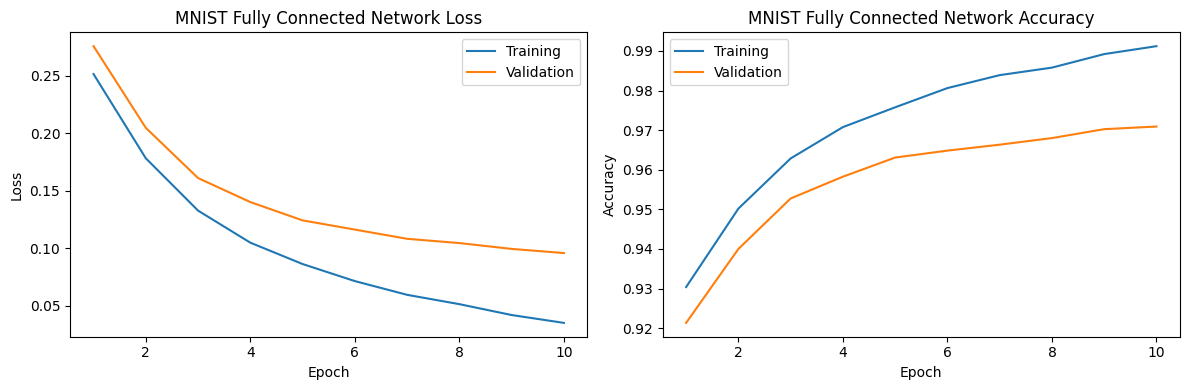

Training time: 52.84 seconds


In [ ]:
MNIST_LEARNING_RATE = 0.001

#Reset the seed before creating the network.
torch.manual_seed(SEED)

mnist_network = create_mnist_network().to(device)

mnist_network, mnist_nn_history, mnist_nn_training_time = train_network(
    mnist_network,
    mnist_train_loader,
    mnist_val_loader,
    MNIST_LEARNING_RATE,
    MNIST_EPOCHS,
)

plot_training_curves(
    mnist_nn_history,
    "MNIST Fully Connected Network"
)

print(f"Training time: {mnist_nn_training_time:.2f} seconds")

###5.1.2 Test the MNIST Network

The completed MNIST network is evaluated once on the test set. The test set does not affect the network's weights or training settings.

In [ ]:
loss_function = nn.CrossEntropyLoss()

mnist_nn_test_loss, mnist_nn_test_accuracy = evaluate_network(
    mnist_network,
    mnist_test_loader,
    loss_function,
)

print(f"Test loss: {mnist_nn_test_loss:.4f}")
print(f"Test accuracy: {mnist_nn_test_accuracy:.4f}")

Test loss: 0.0830
Test accuracy: 0.9756


###5.2.1 Train and Compare CIFAR-10 Networks

Three CIFAR-10 networks are trained using Adam learning rates of 0.01, 0.001, and 0.0001. All other settings and starting weights remain fixed. Final validation accuracy is used to select the best learning rate.

Training network with learning rate 0.01
Epoch 1/50 | Train loss: 1.8255 | Train accuracy: 0.3425 | Val loss: 1.8357 | Val accuracy: 0.3390
Epoch 2/50 | Train loss: 1.8345 | Train accuracy: 0.3297 | Val loss: 1.8471 | Val accuracy: 0.3249
Epoch 3/50 | Train loss: 1.7947 | Train accuracy: 0.3466 | Val loss: 1.8141 | Val accuracy: 0.3431
Epoch 4/50 | Train loss: 1.7763 | Train accuracy: 0.3544 | Val loss: 1.7954 | Val accuracy: 0.3473
Epoch 5/50 | Train loss: 1.7502 | Train accuracy: 0.3584 | Val loss: 1.7796 | Val accuracy: 0.3510
Epoch 6/50 | Train loss: 1.8240 | Train accuracy: 0.3310 | Val loss: 1.8442 | Val accuracy: 0.3234
Epoch 7/50 | Train loss: 1.7381 | Train accuracy: 0.3691 | Val loss: 1.7648 | Val accuracy: 0.3595
Epoch 8/50 | Train loss: 1.7639 | Train accuracy: 0.3622 | Val loss: 1.7948 | Val accuracy: 0.3505
Epoch 9/50 | Train loss: 1.7298 | Train accuracy: 0.3822 | Val loss: 1.7534 | Val accuracy: 0.3696
Epoch 10/50 | Train loss: 1.7443 | Train accuracy: 0.3712 | Val loss

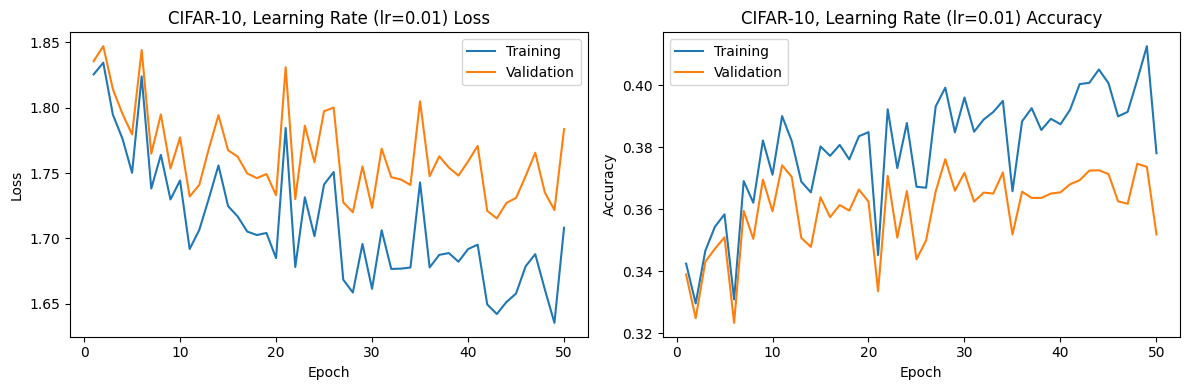

Training network with learning rate 0.001
Epoch 1/50 | Train loss: 1.7368 | Train accuracy: 0.3723 | Val loss: 1.7454 | Val accuracy: 0.3712
Epoch 2/50 | Train loss: 1.6048 | Train accuracy: 0.4353 | Val loss: 1.6232 | Val accuracy: 0.4277
Epoch 3/50 | Train loss: 1.5851 | Train accuracy: 0.4355 | Val loss: 1.6189 | Val accuracy: 0.4274
Epoch 4/50 | Train loss: 1.5059 | Train accuracy: 0.4624 | Val loss: 1.5518 | Val accuracy: 0.4537
Epoch 5/50 | Train loss: 1.4693 | Train accuracy: 0.4746 | Val loss: 1.5299 | Val accuracy: 0.4594
Epoch 6/50 | Train loss: 1.4169 | Train accuracy: 0.4944 | Val loss: 1.4908 | Val accuracy: 0.4668
Epoch 7/50 | Train loss: 1.4070 | Train accuracy: 0.4943 | Val loss: 1.4909 | Val accuracy: 0.4682
Epoch 8/50 | Train loss: 1.3506 | Train accuracy: 0.5189 | Val loss: 1.4544 | Val accuracy: 0.4854
Epoch 9/50 | Train loss: 1.3254 | Train accuracy: 0.5269 | Val loss: 1.4456 | Val accuracy: 0.4900
Epoch 10/50 | Train loss: 1.3560 | Train accuracy: 0.5178 | Val los

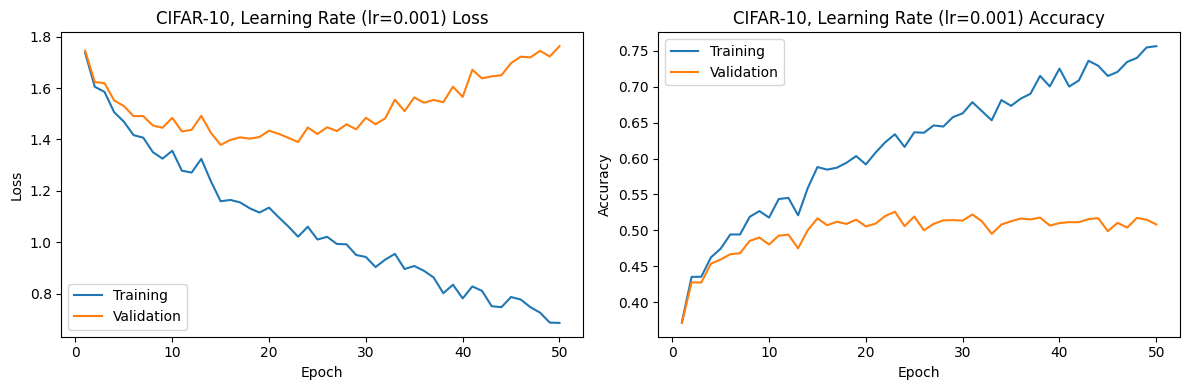

Training network with learning rate 0.0001
Epoch 1/50 | Train loss: 1.8456 | Train accuracy: 0.3449 | Val loss: 1.8495 | Val accuracy: 0.3415
Epoch 2/50 | Train loss: 1.7379 | Train accuracy: 0.3826 | Val loss: 1.7512 | Val accuracy: 0.3763
Epoch 3/50 | Train loss: 1.6558 | Train accuracy: 0.4126 | Val loss: 1.6699 | Val accuracy: 0.4088
Epoch 4/50 | Train loss: 1.6154 | Train accuracy: 0.4281 | Val loss: 1.6347 | Val accuracy: 0.4180
Epoch 5/50 | Train loss: 1.5898 | Train accuracy: 0.4378 | Val loss: 1.6147 | Val accuracy: 0.4270
Epoch 6/50 | Train loss: 1.5494 | Train accuracy: 0.4521 | Val loss: 1.5774 | Val accuracy: 0.4449
Epoch 7/50 | Train loss: 1.5145 | Train accuracy: 0.4669 | Val loss: 1.5490 | Val accuracy: 0.4575
Epoch 8/50 | Train loss: 1.4990 | Train accuracy: 0.4698 | Val loss: 1.5388 | Val accuracy: 0.4534
Epoch 9/50 | Train loss: 1.4781 | Train accuracy: 0.4815 | Val loss: 1.5235 | Val accuracy: 0.4653
Epoch 10/50 | Train loss: 1.4312 | Train accuracy: 0.4939 | Val lo

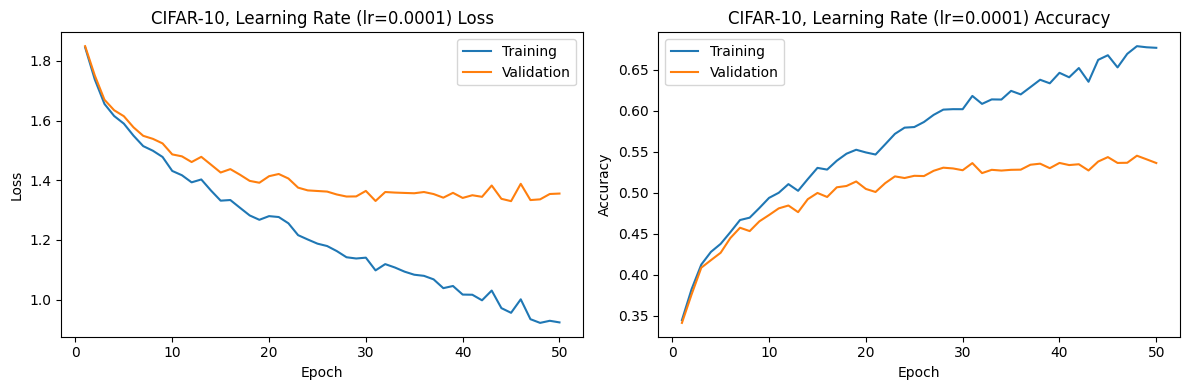

In [ ]:
CIFAR10_LEARNING_RATES = (0.01, 0.001, 0.0001)
# Larger learning rates can learn more quickly, but may prevent convergence

cifar10_nn_results = []
best_cifar10_result = None

for learning_rate in CIFAR10_LEARNING_RATES:
  print(f"Training network with learning rate {learning_rate}")

  # Give every candidate the same starting weights.
  torch.manual_seed(SEED)

  model = create_cifar10_network().to(device)

  model, history, training_time = train_network(
      model,
      cifar10_train_loader,
      cifar10_val_loader,
      learning_rate,
      CIFAR10_EPOCHS,
  )

  final_val_accuracy = history["val_accuracy"][-1]

  result = {
      "Learning rate": learning_rate,
      "Final validation accuracy": final_val_accuracy,
      "Training time (s)": training_time,
      "model": model,
      "history": history,
  }

  cifar10_nn_results.append(result)

  plot_training_curves(
      history,
      f"CIFAR-10, Learning Rate (lr={learning_rate})"
  )

  if (
      best_cifar10_result is None
      or final_val_accuracy > best_cifar10_result["Final validation accuracy"]
  ):
    best_cifar10_result = result


###5.2.2 Test the Selected CIFAR-10 Network

The learning rate with the highest final validation accuracy is selected. Its trained network is evaluated once on the CIFAR-10 test set.

In [ ]:
cifar10_lr_table = pd.DataFrame([
    {
        "Learning rate": result["Learning rate"],
        "Final validation accuracy": result["Final validation accuracy"],
        "Training time (s)": result["Training time (s)"],
    }
    for result in cifar10_nn_results
])

display(
    cifar10_lr_table.style.format({
        "Learning rate": "{:.4f}",
        "Final validation accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

selected_cifar10_learning_rate = best_cifar10_result["Learning rate"]
cifar10_nn_training_time = best_cifar10_result["Training time (s)"]

loss_function = nn.CrossEntropyLoss()

cifar10_nn_test_loss, cifar10_nn_test_accuracy = evaluate_network(
    best_cifar10_result["model"],
    cifar10_test_loader,
    loss_function
)

print(f"Selected learning rate: {selected_cifar10_learning_rate}")
print(f"Test loss: {cifar10_nn_test_loss:.4f}")
print(f"Test accuracy: {cifar10_nn_test_accuracy:.4f}")
print(f"Training time: {cifar10_nn_training_time:.2f} seconds")

,Learning rate,Final validation accuracy,Training time (s)
0,0.0100,0.3519,271.43
1,0.0010,0.5083,272.81
2,0.0001,0.5364,271.95


Selected learning rate: 0.0001
Test loss: 1.3404
Test accuracy: 0.5396
Training time: 271.95 seconds


###5.3 Work Package 4 Results

The final table records each network architecture, selected learning rate, epoch count, final training and validation accuracy, test accuracy, and training time. Training time includes weight training, but excludes the additional evaluation performed after each epoch.

In [ ]:
wp4_results_table = pd.DataFrame([
    {
        "Dataset": "MNIST",
        "Architecture": "784 -> 128 -> 10",
        "Optimizer": "Adam",
        "Learning rate": MNIST_LEARNING_RATE,
        "Epochs": MNIST_EPOCHS,
        "Training accuracy": mnist_nn_history["train_accuracy"][-1],
        "Validation accuracy": mnist_nn_history["val_accuracy"][-1],
        "Test accuracy": mnist_nn_test_accuracy,
        "Training time (s)": mnist_nn_training_time,
    },
    {
        "Dataset": "CIFAR-10",
        "Architecture": "3072 -> 512 -> 256 -> 10",
        "Optimizer": "Adam",
        "Learning rate": selected_cifar10_learning_rate,
        "Epochs": CIFAR10_EPOCHS,
        "Training accuracy": best_cifar10_result["history"]["train_accuracy"][-1],
        "Validation accuracy": best_cifar10_result["history"]["val_accuracy"][-1],
        "Test accuracy": cifar10_nn_test_accuracy,
        "Training time (s)": cifar10_nn_training_time,
    },
])

wp4_results_table.to_csv(
    OUTPUT_DIR / "work_package_4_results.csv",
    index=False
)

display(
    wp4_results_table.style.format({
        "Learning rate": "{:.4f}",
        "Training accuracy": "{:.4f}",
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

,Dataset,Architecture,Optimizer,Learning rate,Epochs,Training accuracy,Validation accuracy,Test accuracy,Training time (s)
0,MNIST,784 -> 128 -> 10,Adam,0.0010,10,0.9912,0.9709,0.9756,52.84
1,CIFAR-10,3072 -> 512 -> 256 -> 10,Adam,0.0001,50,0.6768,0.5364,0.5396,271.95


##6. Work Package 5: Convolutional Neural Networks

Work Package 5 uses convolutional neural networks that process images in their original spatial form. Unlike the fully connected networks, the images are not flattened before feature extraction. Convolutional layers examine neighboring pixels and learn spatial features such as edges, textures, and shapes. Two convolutional blocks are used, with each containing a convolutional layer, ReLU activation, and pooling.

###6.0.1 Define the CNNs

Both networks use two convolutional blocks. MNIST accepts one grayscale channel, while CIFAR-10 accepts three RGB channels. Each convolutional layer uses padding to preserve the image width and height before pooling reduces both dimensions by half. The final feature maps are flattened and passed through fully connected layers to produce ten class scores.

In [ ]:
MNIST_CNN_EPOCHS = 10
CIFAR10_CNN_EPOCHS = 50
CNN_LEARNING_RATE = 0.001


def create_mnist_cnn():
  """Create a convolutional neural network for MNIST."""
  return nn.Sequential(
      nn.Conv2d(1, 32, kernel_size=3, padding=1),
      # in_channel=1, out_channels(filters)=32
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2), # Spatial dimensions reduced by half

      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      # Classifier reduces tensor to flattened
      nn.Flatten(),
      nn.Linear(64 * 7 * 7, 128), # Size has been reduced to 7 x 7
      nn.ReLU(),
      nn.Linear(128, 10),
  )


def create_cifar10_cnn():
  """Create a convolutional neural network for CIFAR-10."""
  return nn.Sequential(
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      nn.Flatten(),
      nn.Linear(64 * 8 * 8, 128),
      nn.ReLU(),
      nn.Linear(128, 10),
  )


print(create_mnist_cnn())
print(create_cifar10_cnn())

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=3136, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=10, bias=True)
)
Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=128, bias=True)
  (8): ReLU()
  (9): Line

###6.0.2 Collect Predictions and Display Results

These functions collect predictions from trained CNN, create a confusion matrix, and display correctly and incorrectly classified test images.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def collect_predictions(model, data_loader):
  """Return the true and predicted labels from a DataLoader."""
  model.eval()

  all_labels = []
  all_predictions = []

  with torch.no_grad():
    for images, labels in data_loader:
      images = images.to(device)

      scores = model(images)
      predictions = scores.argmax(dim=1)

      all_labels.extend(labels.numpy())
      all_predictions.extend(predictions.cpu().numpy())

  return np.asarray(all_labels), np.asarray(all_predictions)


def display_confusion_matrix(true_labels, predictions, class_names, title):
  """Display a confusion matrix."""
  matrix = confusion_matrix(true_labels, predictions)

  figure, axis = plt.subplots(figsize=(8, 8))
  display = ConfusionMatrixDisplay(
      confusion_matrix=matrix,
      display_labels=class_names,
  )
  display.plot(ax=axis, cmap="Blues", colorbar=False)
  axis.set_title(title)
  plt.show()


def display_example_predictions(
    dataset,
    predictions,
    class_names,
    title,
):
  """Display five correct and five incorrect predictions."""
  true_labels = np.asarray(dataset.targets)

  correct_indices = np.where(predictions == true_labels)[0][:5]
  incorrect_indices = np.where(predictions != true_labels)[0][:5]

  figure, axes = plt.subplots(2, 5, figsize=(12, 5))

  for row, indices in enumerate([correct_indices, incorrect_indices]):
    for column, index in enumerate(indices):
      image, true_label = dataset[index]

      if image.shape[0] == 1:
        axes[row, column].imshow(image.squeeze(), cmap="gray")
      else:
        axes[row, column].imshow(image.permute(1, 2, 0))

      predicted_label = predictions[index]

      axes[row, column].set_title(
          f"True: {class_names[true_label]}\n"
          f"Predicted: {class_names[predicted_label]}"
      )
      axes[row, column].axis("off")

  figure.suptitle(title)
  plt.tight_layout()
  plt.show()

###6.1 CNN - MNIST

The MNIST CNN is trained using Adam, cross-entropy loss, a learning rate of 0.001, and the existing batch size. Its training and validation measurements are recorded after each epoch.

Epoch 1/10 | Train loss: 0.0865 | Train accuracy: 0.9727 | Val loss: 0.1057 | Val accuracy: 0.9677
Epoch 2/10 | Train loss: 0.0426 | Train accuracy: 0.9872 | Val loss: 0.0605 | Val accuracy: 0.9825
Epoch 3/10 | Train loss: 0.0405 | Train accuracy: 0.9877 | Val loss: 0.0607 | Val accuracy: 0.9821
Epoch 4/10 | Train loss: 0.0236 | Train accuracy: 0.9926 | Val loss: 0.0497 | Val accuracy: 0.9846
Epoch 5/10 | Train loss: 0.0219 | Train accuracy: 0.9926 | Val loss: 0.0543 | Val accuracy: 0.9862
Epoch 6/10 | Train loss: 0.0191 | Train accuracy: 0.9940 | Val loss: 0.0469 | Val accuracy: 0.9869
Epoch 7/10 | Train loss: 0.0149 | Train accuracy: 0.9951 | Val loss: 0.0505 | Val accuracy: 0.9864
Epoch 8/10 | Train loss: 0.0137 | Train accuracy: 0.9952 | Val loss: 0.0515 | Val accuracy: 0.9857
Epoch 9/10 | Train loss: 0.0067 | Train accuracy: 0.9979 | Val loss: 0.0453 | Val accuracy: 0.9892
Epoch 10/10 | Train loss: 0.0110 | Train accuracy: 0.9960 | Val loss: 0.0577 | Val accuracy: 0.9869


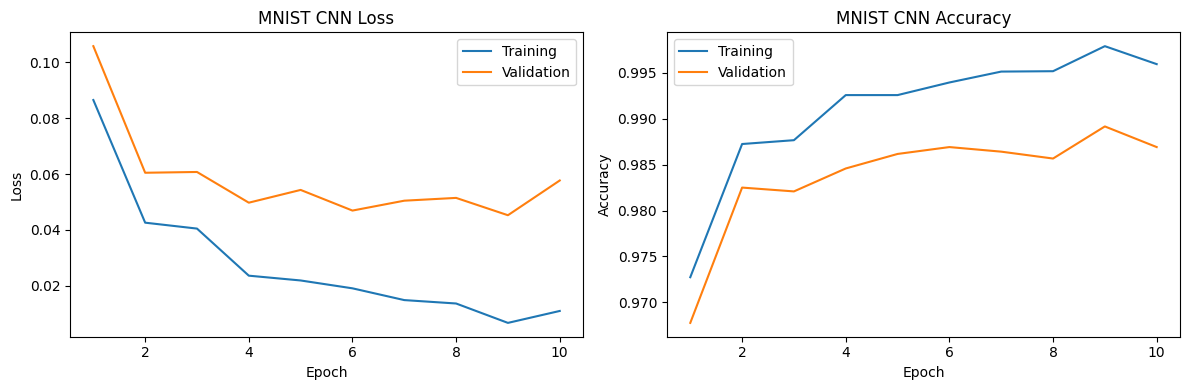

In [ ]:
torch.manual_seed(SEED)

mnist_cnn = create_mnist_cnn().to(device)

mnist_cnn, mnist_cnn_history, mnist_cnn_training_time = train_network(
    mnist_cnn, # Receives full image tensor
    mnist_train_loader,
    mnist_val_loader,
    learning_rate=CNN_LEARNING_RATE,
    epochs=MNIST_CNN_EPOCHS,
)

plot_training_curves(
    mnist_cnn_history,
    "MNIST CNN",
)

### 6.1.1 Test and Inspect the MNIST CNN

Test loss: 0.0384
Test accuracy: 0.9885
Training time: 57.16 seconds


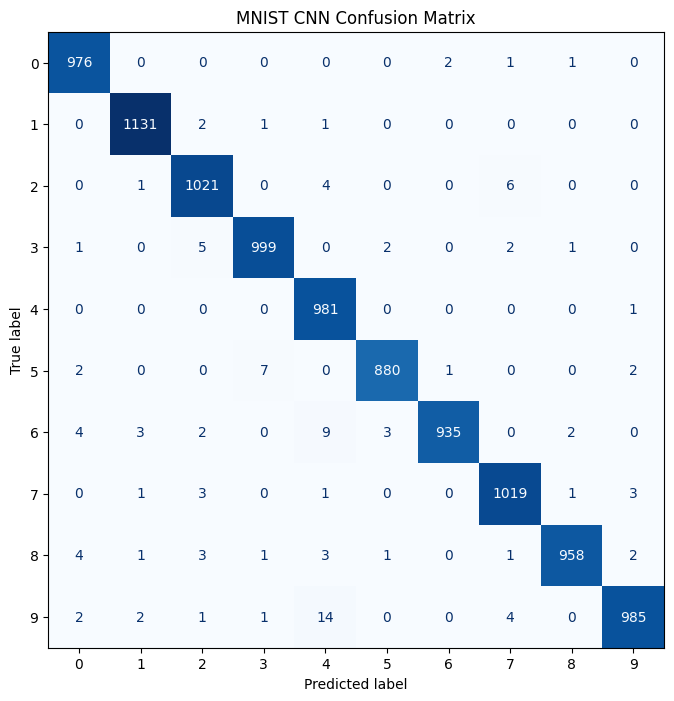

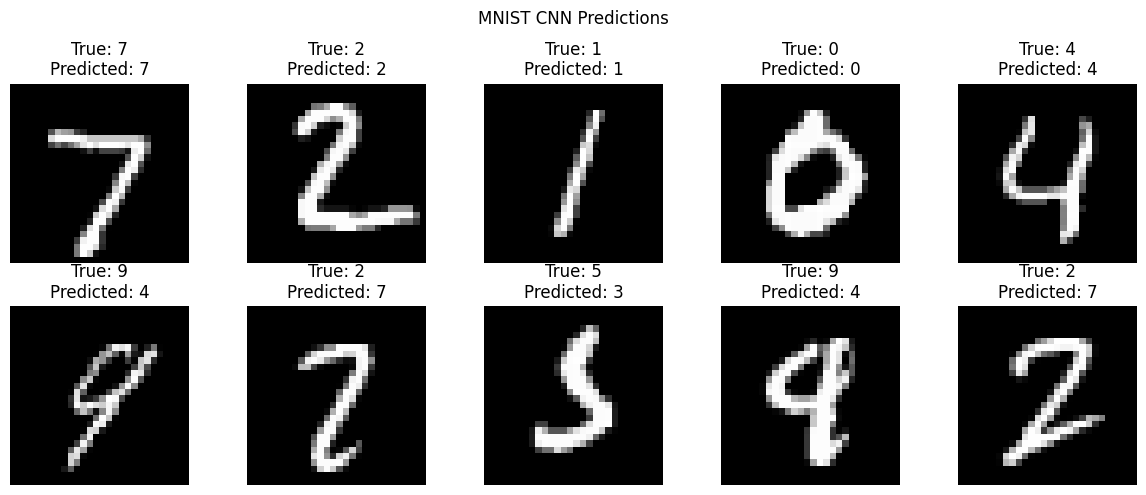

In [ ]:
loss_function = nn.CrossEntropyLoss()

mnist_cnn_test_loss, mnist_cnn_test_accuracy = evaluate_network(
    mnist_cnn,
    mnist_test_loader,
    loss_function,
)

mnist_cnn_true_labels, mnist_cnn_predictions = collect_predictions(
    mnist_cnn,
    mnist_test_loader,
)

print(f"Test loss: {mnist_cnn_test_loss:.4f}")
print(f"Test accuracy: {mnist_cnn_test_accuracy:.4f}")
print(f"Training time: {mnist_cnn_training_time:.2f} seconds")

MNIST_CLASS_NAMES = [str(number) for number in range(10)]

display_confusion_matrix(
    mnist_cnn_true_labels,
    mnist_cnn_predictions,
    MNIST_CLASS_NAMES,
    "MNIST CNN Confusion Matrix",
)

display_example_predictions(
    mnist_test,
    mnist_cnn_predictions,
    MNIST_CLASS_NAMES,
    "MNIST CNN Predictions",
)

### 6.2 CNN - CIFAR-10

The CIFAR-10 CNN receives the original three-channel image tensors. It uses the same two-block structure as the MNIST CNN but accepts RGB input and produces larger feature maps before the fully connected layers.

Epoch 1/50 | Train loss: 1.3721 | Train accuracy: 0.5118 | Val loss: 1.3920 | Val accuracy: 0.5041
Epoch 2/50 | Train loss: 1.2146 | Train accuracy: 0.5718 | Val loss: 1.2572 | Val accuracy: 0.5593
Epoch 3/50 | Train loss: 1.0679 | Train accuracy: 0.6205 | Val loss: 1.1268 | Val accuracy: 0.6012
Epoch 4/50 | Train loss: 0.9679 | Train accuracy: 0.6614 | Val loss: 1.0532 | Val accuracy: 0.6308
Epoch 5/50 | Train loss: 0.9090 | Train accuracy: 0.6804 | Val loss: 1.0160 | Val accuracy: 0.6422
Epoch 6/50 | Train loss: 0.8107 | Train accuracy: 0.7188 | Val loss: 0.9452 | Val accuracy: 0.6729
Epoch 7/50 | Train loss: 0.7614 | Train accuracy: 0.7363 | Val loss: 0.9299 | Val accuracy: 0.6782
Epoch 8/50 | Train loss: 0.7829 | Train accuracy: 0.7271 | Val loss: 0.9752 | Val accuracy: 0.6704
Epoch 9/50 | Train loss: 0.7322 | Train accuracy: 0.7415 | Val loss: 0.9538 | Val accuracy: 0.6704
Epoch 10/50 | Train loss: 0.6474 | Train accuracy: 0.7752 | Val loss: 0.9180 | Val accuracy: 0.6859
Epoch 11/

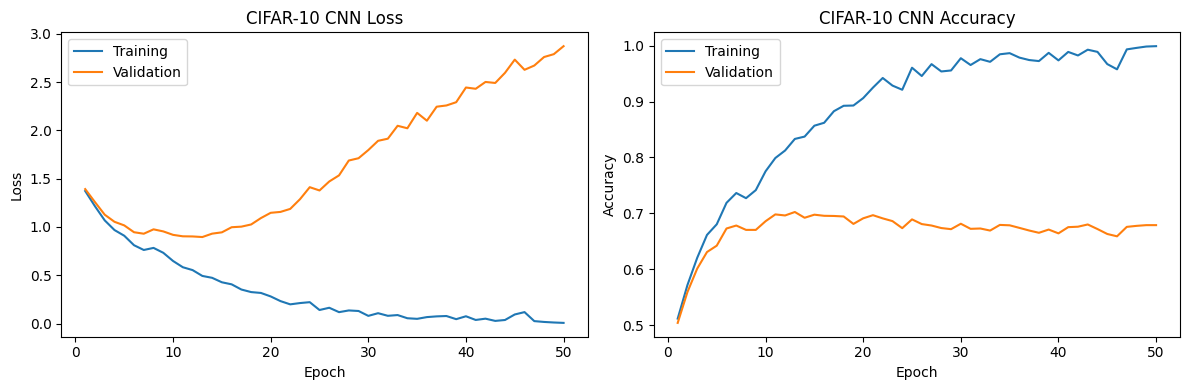

In [ ]:
torch.manual_seed(SEED)

cifar10_cnn = create_cifar10_cnn().to(device)

cifar10_cnn, cifar10_cnn_history, cifar10_cnn_training_time = train_network(
    cifar10_cnn,
    cifar10_train_loader,
    cifar10_val_loader,
    learning_rate=CNN_LEARNING_RATE,
    epochs=CIFAR10_CNN_EPOCHS,
)

plot_training_curves(
    cifar10_cnn_history,
    "CIFAR-10 CNN",
)

### 6.2.1 Test and Inspect the CIFAR-10 CNN

Test loss: 2.9380
Test accuracy: 0.6788
Training time: 275.75 seconds


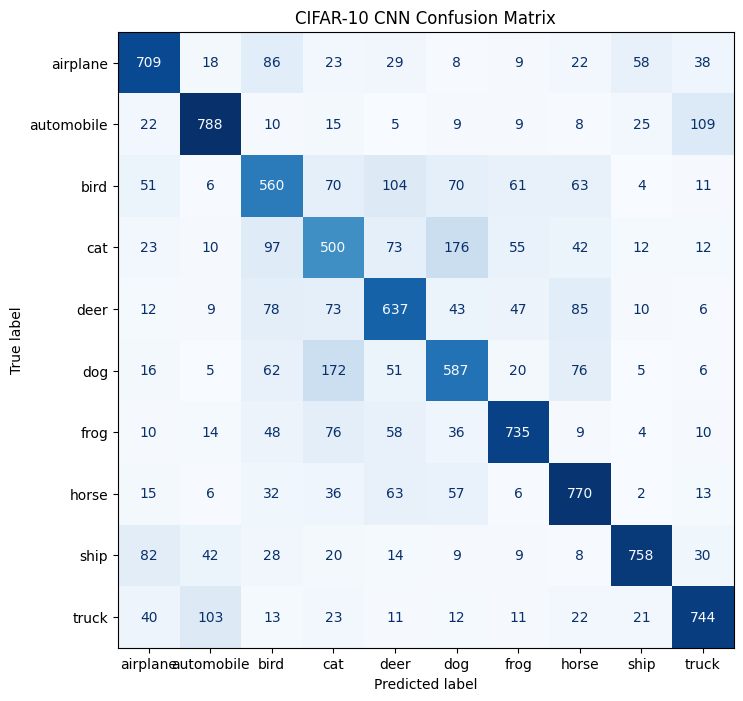

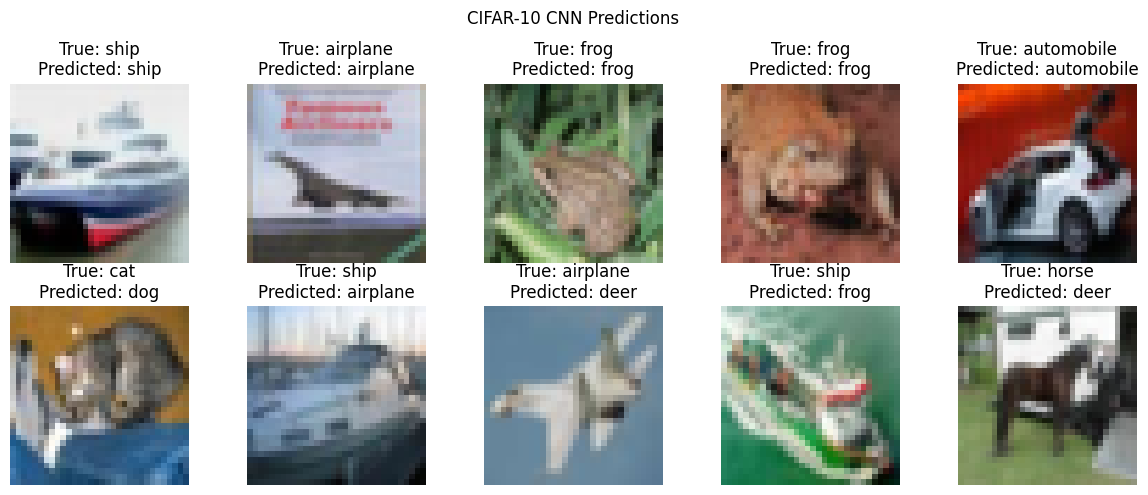

In [ ]:
cifar10_cnn_test_loss, cifar10_cnn_test_accuracy = evaluate_network(
    cifar10_cnn,
    cifar10_test_loader,
    loss_function,
)

cifar10_cnn_true_labels, cifar10_cnn_predictions = collect_predictions(
    cifar10_cnn,
    cifar10_test_loader,
)

print(f"Test loss: {cifar10_cnn_test_loss:.4f}")
print(f"Test accuracy: {cifar10_cnn_test_accuracy:.4f}")
print(f"Training time: {cifar10_cnn_training_time:.2f} seconds")

CIFAR10_CLASS_NAMES = cifar10_test.classes

display_confusion_matrix(
    cifar10_cnn_true_labels,
    cifar10_cnn_predictions,
    CIFAR10_CLASS_NAMES,
    "CIFAR-10 CNN Confusion Matrix",
)

display_example_predictions(
    cifar10_test,
    cifar10_cnn_predictions,
    CIFAR10_CLASS_NAMES,
    "CIFAR-10 CNN Predictions",
)

### 6.3 Work Package 5 Results

In [ ]:
wp5_results_table = pd.DataFrame([
    {
        "Dataset": "MNIST",
        "Architecture": "Conv 1-32, Conv 32-64, FC 128-10",
        "Learning rate": CNN_LEARNING_RATE,
        "Epochs": MNIST_CNN_EPOCHS,
        "Training accuracy": mnist_cnn_history["train_accuracy"][-1],
        "Validation accuracy": mnist_cnn_history["val_accuracy"][-1],
        "Test accuracy": mnist_cnn_test_accuracy,
        "Training time (s)": mnist_cnn_training_time,
    },
    {
        "Dataset": "CIFAR-10",
        "Architecture": "Conv 3-32, Conv 32-64, FC 128-10",
        "Learning rate": CNN_LEARNING_RATE,
        "Epochs": CIFAR10_CNN_EPOCHS,
        "Training accuracy": cifar10_cnn_history["train_accuracy"][-1],
        "Validation accuracy": cifar10_cnn_history["val_accuracy"][-1],
        "Test accuracy": cifar10_cnn_test_accuracy,
        "Training time (s)": cifar10_cnn_training_time,
    },
])

wp5_results_table.to_csv(
    OUTPUT_DIR / "work_package_5_results.csv",
    index=False,
)

display(
    wp5_results_table.style.format({
        "Learning rate": "{:.4f}",
        "Training accuracy": "{:.4f}",
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

,Dataset,Architecture,Learning rate,Epochs,Training accuracy,Validation accuracy,Test accuracy,Training time (s)
0,MNIST,"Conv 1-32, Conv 32-64, FC 128-10",0.0010,10,0.9960,0.9869,0.9885,57.16
1,CIFAR-10,"Conv 3-32, Conv 32-64, FC 128-10",0.0010,50,0.9990,0.6789,0.6788,275.75


##7. Work Package 6: Cross-Pipeline Synthesis

This section combines the final results from all five classification pipelines. It also displays confusion matrices for the selected HOG + Linear SVM models.

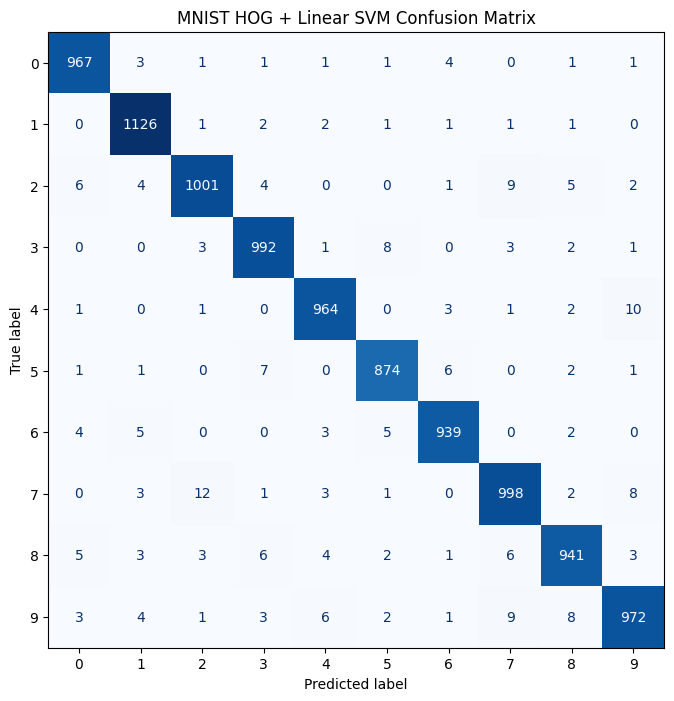

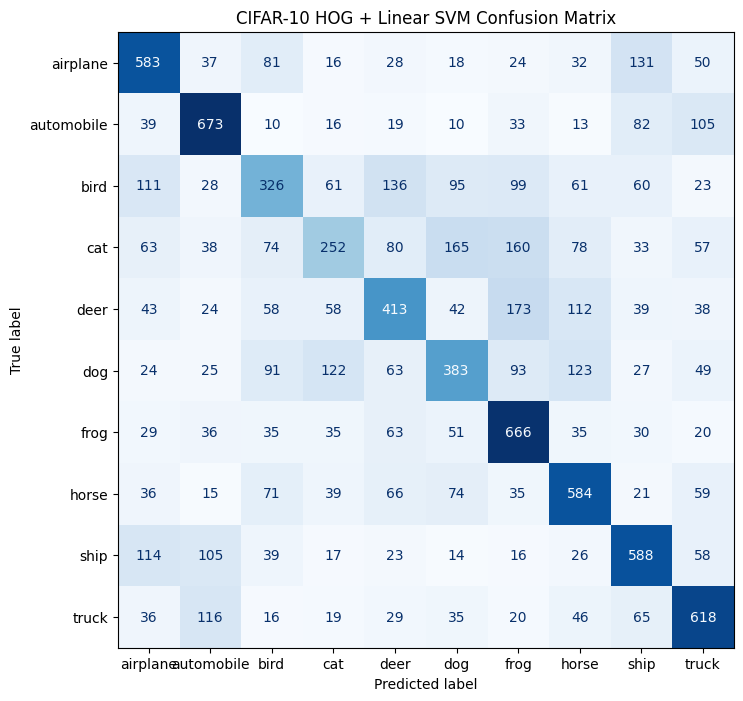

In [ ]:
# Generate predictions from the selected HOG + Linear SVM models
mnist_svm_predictions = mnist_svm_best["model"].predict(
    mnist_hog_test_features
)

cifar10_svm_predictions = cifar_svm_best["model"].predict(
    cifar_hog_test_features
)

# Display the two required classical-model confusion matrices
display_confusion_matrix(
    mnist_hog_test_labels,
    mnist_svm_predictions,
    MNIST_CLASS_NAMES,
    "MNIST HOG + Linear SVM Confusion Matrix",
)

display_confusion_matrix(
    cifar_hog_test_labels,
    cifar10_svm_predictions,
    CIFAR10_CLASS_NAMES,
    "CIFAR-10 HOG + Linear SVM Confusion Matrix",
)

###7.1 Consolidated Results

The following table contains the final selected pipeline from each work package for both datasets. Candidate hyperparameter settings are not included because they are not separate final pipelines.

In [ ]:
final_results_table = pd.DataFrame([
    {
        "Dataset": "MNIST",
        "Representation": "Raw pixels",
        "Classifier": "Logistic regression",
        "Selected settings": "784 features, C=1.0",
        "Validation accuracy": mnist_val_accuracy,
        "Test accuracy": mnist_test_accuracy,
        "Training time (s)": mnist_training_time,
    },
    {
        "Dataset": "MNIST",
        "Representation": "HOG",
        "Classifier": "Logistic regression",
        "Selected settings": "12 orientations, 1728 features",
        "Validation accuracy": mnist_hog_best["Validation Accuracy"],
        "Test accuracy": mnist_hog_test_accuracy,
        "Training time (s)": mnist_hog_best["Training Time (s)"],
    },
    {
        "Dataset": "MNIST",
        "Representation": "HOG",
        "Classifier": "Linear SVM",
        "Selected settings": "12 orientations, C=0.1",
        "Validation accuracy": mnist_svm_best["Validation Accuracy"],
        "Test accuracy": mnist_svm_test_accuracy,
        "Training time (s)": mnist_svm_best["Training Time (s)"],
    },
    {
        "Dataset": "MNIST",
        "Representation": "Flattened pixels",
        "Classifier": "Fully connected network",
        "Selected settings": "784 -> 128 -> 10, lr=0.001, 10 epochs",
        "Validation accuracy": mnist_nn_history["val_accuracy"][-1],
        "Test accuracy": mnist_nn_test_accuracy,
        "Training time (s)": mnist_nn_training_time,
    },
    {
        "Dataset": "MNIST",
        "Representation": "Spatial tensor",
        "Classifier": "CNN",
        "Selected settings": "32-64 channels, lr=0.001, 10 epochs",
        "Validation accuracy": mnist_cnn_history["val_accuracy"][-1],
        "Test accuracy": mnist_cnn_test_accuracy,
        "Training time (s)": mnist_cnn_training_time,
    },

    {
        "Dataset": "CIFAR-10",
        "Representation": "Raw pixels",
        "Classifier": "Logistic regression",
        "Selected settings": "3072 features, C=1.0",
        "Validation accuracy": cifar10_val_accuracy,
        "Test accuracy": cifar10_test_accuracy,
        "Training time (s)": cifar10_training_time,
    },
    {
        "Dataset": "CIFAR-10",
        "Representation": "HOG grayscale",
        "Classifier": "Logistic regression",
        "Selected settings": "6 orientations, 1176 features",
        "Validation accuracy": cifar_hog_best["Validation Accuracy"],
        "Test accuracy": cifar_hog_test_accuracy,
        "Training time (s)": cifar_hog_best["Training Time (s)"],
    },
    {
        "Dataset": "CIFAR-10",
        "Representation": "HOG grayscale",
        "Classifier": "Linear SVM",
        "Selected settings": "6 orientations, C=0.1",
        "Validation accuracy": cifar_svm_best["Validation Accuracy"],
        "Test accuracy": cifar_svm_test_accuracy,
        "Training time (s)": cifar_svm_best["Training Time (s)"],
    },
    {
        "Dataset": "CIFAR-10",
        "Representation": "Flattened pixels",
        "Classifier": "Fully connected network",
        "Selected settings": "3072 -> 512 -> 256 -> 10, lr=0.0001, 50 epochs",
        "Validation accuracy": best_cifar10_result["Final validation accuracy"],
        "Test accuracy": cifar10_nn_test_accuracy,
        "Training time (s)": cifar10_nn_training_time,
    },
    {
        "Dataset": "CIFAR-10",
        "Representation": "Spatial RGB tensor",
        "Classifier": "CNN",
        "Selected settings": "32-64 channels, lr=0.001, 50 epochs",
        "Validation accuracy": cifar10_cnn_history["val_accuracy"][-1],
        "Test accuracy": cifar10_cnn_test_accuracy,
        "Training time (s)": cifar10_cnn_training_time,
    },
])

display(
    final_results_table.style.format({
        "Validation accuracy": "{:.4f}",
        "Test accuracy": "{:.4f}",
        "Training time (s)": "{:.2f}",
    })
)

,Dataset,Representation,Classifier,Selected settings,Validation accuracy,Test accuracy,Training time (s)
0,MNIST,Raw pixels,Logistic regression,"784 features, C=1.0",0.9136,0.9230,11.86
1,MNIST,HOG,Logistic regression,"12 orientations, 1728 features",0.9771,0.9786,6.49
2,MNIST,HOG,Linear SVM,"12 orientations, C=0.1",0.9764,0.9774,334.55
3,MNIST,Flattened pixels,Fully connected network,"784 -> 128 -> 10, lr=0.001, 10 epochs",0.9709,0.9756,52.84
4,MNIST,Spatial tensor,CNN,"32-64 channels, lr=0.001, 10 epochs",0.9869,0.9885,57.16
5,CIFAR-10,Raw pixels,Logistic regression,"3072 features, C=1.0",0.3624,0.3655,283.31
6,CIFAR-10,HOG grayscale,Logistic regression,"6 orientations, 1176 features",0.5157,0.5084,27.09
7,CIFAR-10,HOG grayscale,Linear SVM,"6 orientations, C=0.1",0.5175,0.5086,234.68
8,CIFAR-10,Flattened pixels,Fully connected network,"3072 -> 512 -> 256 -> 10, lr=0.0001, 50 epochs",0.5364,0.5396,271.95
9,CIFAR-10,Spatial RGB tensor,CNN,"32-64 channels, lr=0.001, 50 epochs",0.6789,0.6788,275.75
